<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Histogram**


Estimated time needed: **45** minutes


In this lab, you will focus on the visualization of data. The dataset will be provided through an RDBMS, and you will need to use SQL queries to extract the required data.


## Objectives


In this lab, you will perform the following:


- Visualize the distribution of data using histograms.

- Visualize relationships between features.

- Explore data composition and comparisons.


## Demo: Working with database


#### Download the database file.


In [1]:
!wget -O survey-data.sqlite https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/QR9YeprUYhOoLafzlLspAw/survey-results-public.sqlite

"wget" non � riconosciuto come comando interno o esterno,
 un programma eseguibile o un file batch.


#### Install the required libraries and import them


In [2]:
!pip install pandas


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
!pip install matplotlib


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#### Connect to the SQLite database


In [5]:
conn = sqlite3.connect('survey-data.sqlite')

## Demo: Basic SQL queries

**Demo 1: Count the number of rows in the table**


In [6]:
QUERY = "SELECT COUNT(*) FROM main"
df = pd.read_sql_query(QUERY, conn)
print(df)


   COUNT(*)
0     65437


**Demo 2: List all tables**


In [8]:
QUERY = """
SELECT name as Table_Name 
FROM sqlite_master 
WHERE type = 'table'
"""
pd.read_sql_query(QUERY, conn)


,Table_Name
0,main


**Demo 3: Group data by age**


In [10]:
survey_df=pd.read_sql_query("SELECT * FROM main", conn)

QUERY = """
SELECT Age, COUNT(*) as count 
FROM main 
GROUP BY Age 
ORDER BY Age
"""
df_age = pd.read_sql_query(QUERY, conn)
print(df_age)


                  Age  count
0     18-24 years old  14098
1     25-34 years old  23911
2     35-44 years old  14942
3     45-54 years old   6249
4     55-64 years old   2575
5   65 years or older    772
6   Prefer not to say    322
7  Under 18 years old   2568


## Hands-on Lab: Visualizing Data with Histograms


### 1. Visualizing the distribution of data (Histograms)


**1.1 Histogram of `CompTotal` (Total Compensation)**


Objective: Plot a histogram of `CompTotal` to visualize the distribution of respondents' total compensation.


Number of valid CompTotal values: 33613
count     3.361300e+04
mean     2.975039e+145
std      5.454392e+147
min       1.000000e+00
25%       6.000000e+04
50%       1.100000e+05
75%       2.500000e+05
max      1.000000e+150
Name: CompTotal, dtype: float64


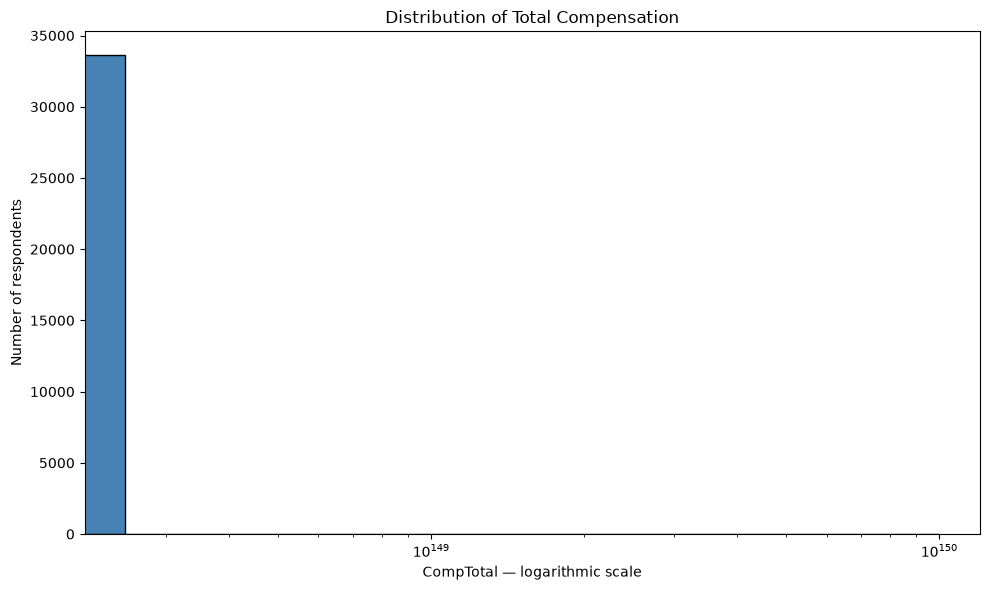

In [20]:
## Write your code here
# Copia del dataset originale
comp_df = survey_df.copy()

# Conversione numerica
comp_df["CompTotal"] = pd.to_numeric(
    comp_df["CompTotal"],
    errors="coerce"
)

# Rimuove valori mancanti e compensi non positivi
comp_df = comp_df.dropna(subset=["CompTotal"])
comp_df = comp_df[comp_df["CompTotal"] > 0]

print("Number of valid CompTotal values:", len(comp_df))
print(comp_df["CompTotal"].describe())

# Istogramma con scala logaritmica
plt.figure(figsize=(10, 6))

plt.hist(
    comp_df["CompTotal"],
    bins=40,
    color="steelblue",
    edgecolor="black"
)

plt.xscale("log")
plt.title("Distribution of Total Compensation")
plt.xlabel("CompTotal — logarithmic scale")
plt.ylabel("Number of respondents")
plt.tight_layout()
plt.show()

**1.2 Histogram of YearsCodePro (Years of Professional Coding Experience)**


Objective: Plot a histogram of `YearsCodePro` to analyze the distribution of coding experience among respondents.


count    51610.000000
mean        10.212013
std          9.079437
min          0.500000
25%          3.000000
50%          7.000000
75%         15.000000
max         51.000000
Name: YearsCodePro, dtype: float64


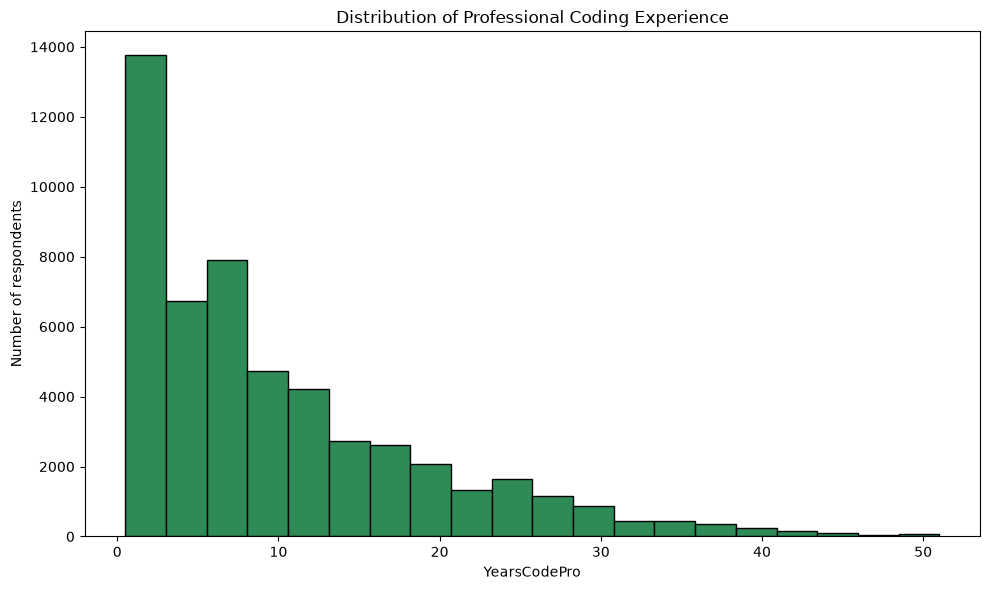

In [12]:
## Write your code here
years_pro=(survey_df['YearsCodePro'].replace({'Less than 1 year': '0.5','More than 50 years': '51'}).pipe(pd.to_numeric, errors='coerce'))
print(years_pro.describe())

plt.figure(figsize=(10,6))
plt.hist(years_pro.dropna(), bins=20, color='seagreen', edgecolor='black')
plt.title('Distribution of Professional Coding Experience')
plt.xlabel('YearsCodePro')
plt.ylabel('Number of respondents')
plt.tight_layout()
plt.show()

### 2. Visualizing Relationships in Data


**2.1 Histogram Comparison of `CompTotal` by `Age` Group**


Objective: Use histograms to compare the distribution of CompTotal across different Age groups.


Top 5 most common age groups: ['25-34 years old', '35-44 years old', '18-24 years old', '45-54 years old', '55-64 years old']
Age
25-34 years old    14624
35-44 years old     9324
18-24 years old     4606
45-54 years old     3495
55-64 years old     1272
Name: count, dtype: int64


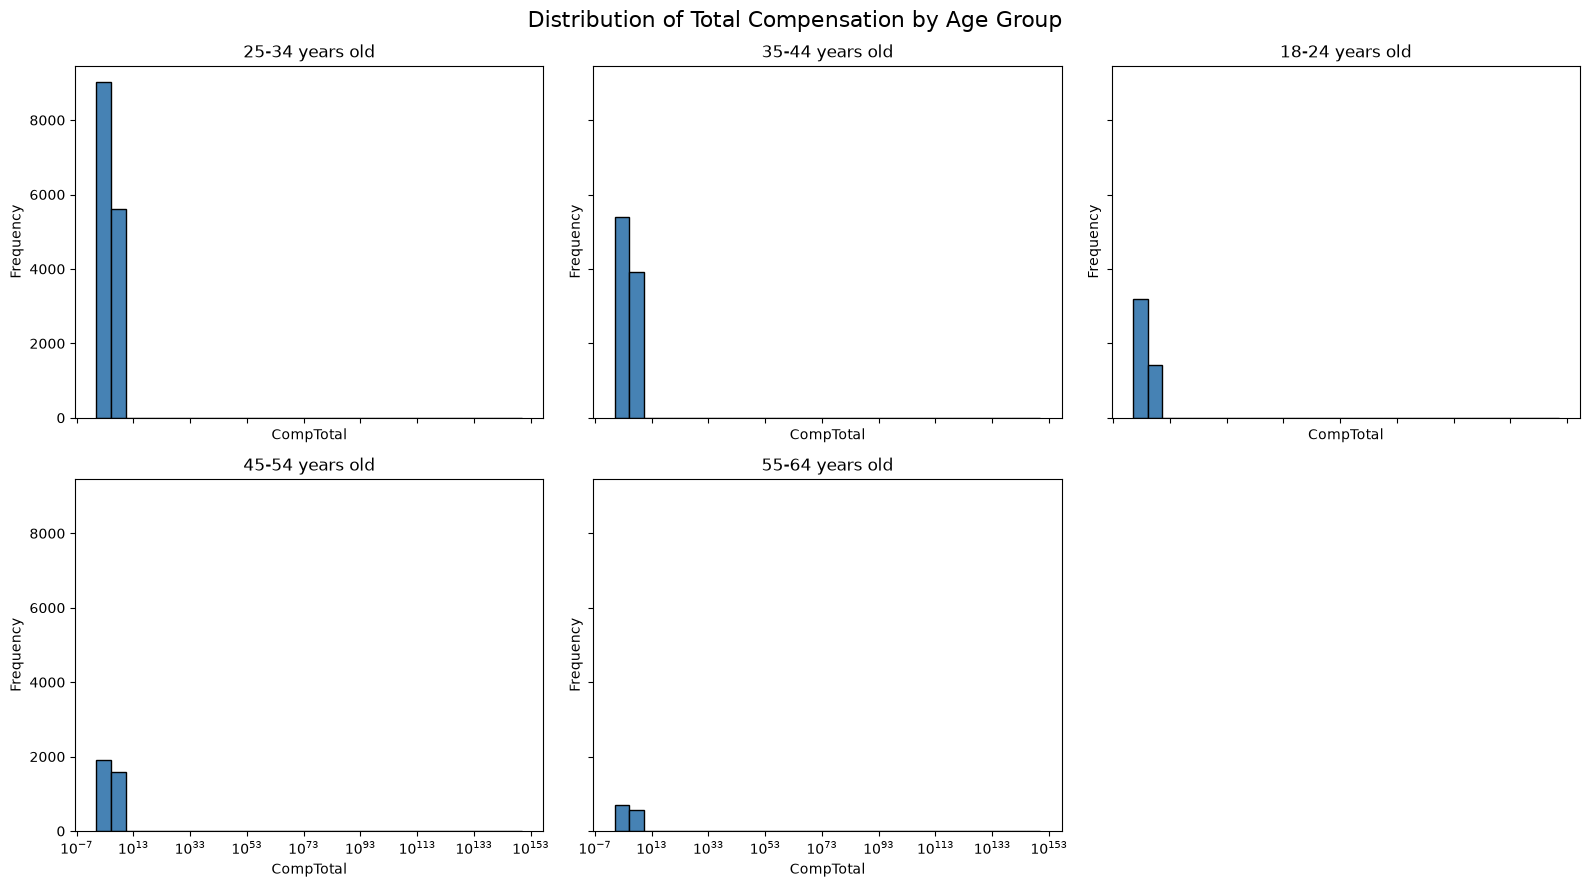

In [18]:
## Write your code here
comparison_df=survey_df.copy()

#Convert 'CompTotal' to numeric
comparison_df['CompTotal'] = pd.to_numeric(comparison_df['CompTotal'], errors='coerce')
#Drop rows with NaN values in 'CompTotal'
comparison_df = comparison_df.dropna(subset=['Age','CompTotal'])

comparison_df=comparison_df[comparison_df['CompTotal']>0]

#select the top 5 most frequent age groups
age_groups = (comparison_df['Age'].value_counts().head(5).index.to_list())

print("Top 5 most common age groups:", age_groups)

# verify the number of observations in each group
print(comparison_df[comparison_df['Age'].isin(age_groups)]['Age'].value_counts())

#Use common logarithmic bins for all groups
min_comp = comparison_df['CompTotal'].min()
max_comp = comparison_df['CompTotal'].max()

bins=np.logspace(np.log10(min_comp), np.log10(max_comp), 30) # Create logarithmic bins

#Create a subplot for each age group
fig,axes=plt.subplots(nrows=2,ncols=3,figsize=(16,9), sharex=True, sharey=True)

axes=axes.flatten() # Flatten the axes array for easy iteration

for i, age_group in enumerate(age_groups):
    values = comparison_df.loc[comparison_df['Age']==age_group, 'CompTotal'] 
    
    axes[i].hist(values, bins=bins, edgecolor='black',color='steelblue')
    
    axes[i].set_title(age_group)
    axes[i].set_xlabel('CompTotal')
    axes[i].set_ylabel('Frequency')
    axes[i].set_xscale('log') # Set x-axis to logarithmic scale

for j in range(len(age_groups), len(axes)):
    axes[j].set_visible(False) # Hide unused subplots
    
fig.suptitle('Distribution of Total Compensation by Age Group', fontsize=16)
plt.tight_layout()
plt.show()




**2.2 Histogram of TimeSearching for Different Age Groups**


Objective: Use histograms to explore the distribution of `TimeSearching` (time spent searching for information) for respondents across different age groups.


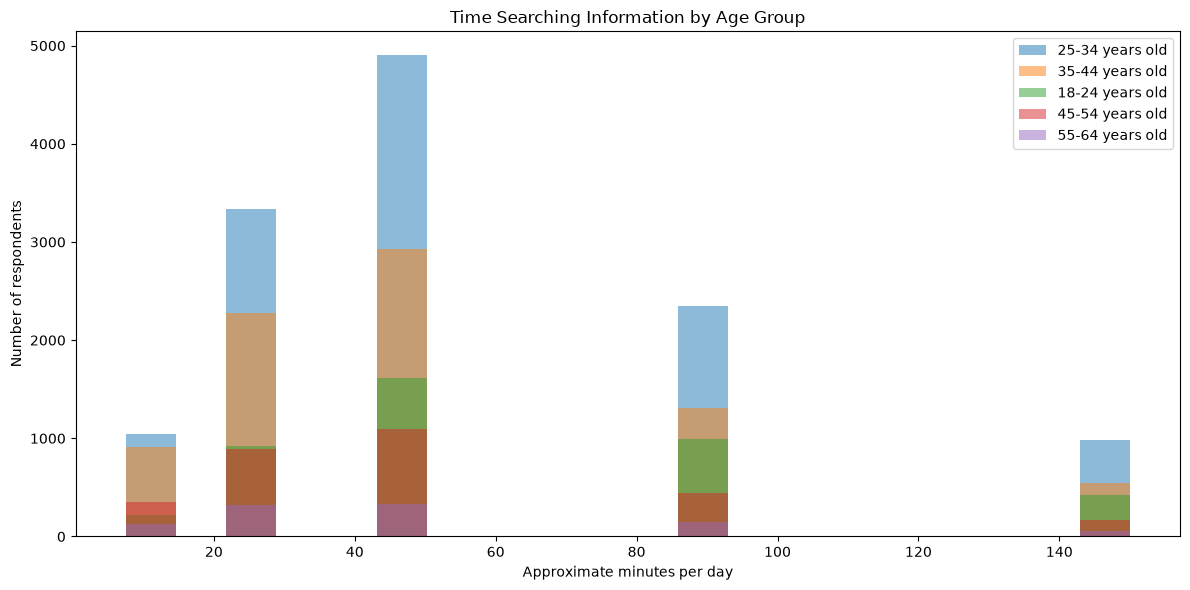

In [24]:
## Write your code here
time_mapping = {
    'Less than 15 minutes a day': 7.5, '15-30 minutes a day': 22.5,
    '30-60 minutes a day': 45, '60-120 minutes a day': 90,
    'Over 120 minutes a day': 150
}
search_df=pd.DataFrame({
    'TimeSearching_minutes': survey_df['TimeSearching'].map(time_mapping),
    'Age': survey_df['Age']
}).dropna()

age_groups = search_df['Age'].value_counts().head(5).index # Get the top 5 most common age groups

plt.figure(figsize=(12,6))
for age_group in age_groups:
    values = search_df[search_df['Age'] == age_group]['TimeSearching_minutes']
    plt.hist(values, bins=20, alpha=0.5, label=age_group)
    
plt.title('Time Searching Information by Age Group')
plt.xlabel('Approximate minutes per day')
plt.ylabel('Number of respondents')
plt.legend()
plt.tight_layout()
plt.show()

### 3. Visualizing the Composition of Data


**3.1 Histogram of Most Desired Databases (`DatabaseWantToWorkWith`)**


Objective: Visualize the most desired databases for future learning using a histogram of the top 5 databases.


DatabaseWantToWorkWith
PostgreSQL    24005
SQLite        13489
MySQL         12269
MongoDB       10982
Redis         10847
Name: count, dtype: int64


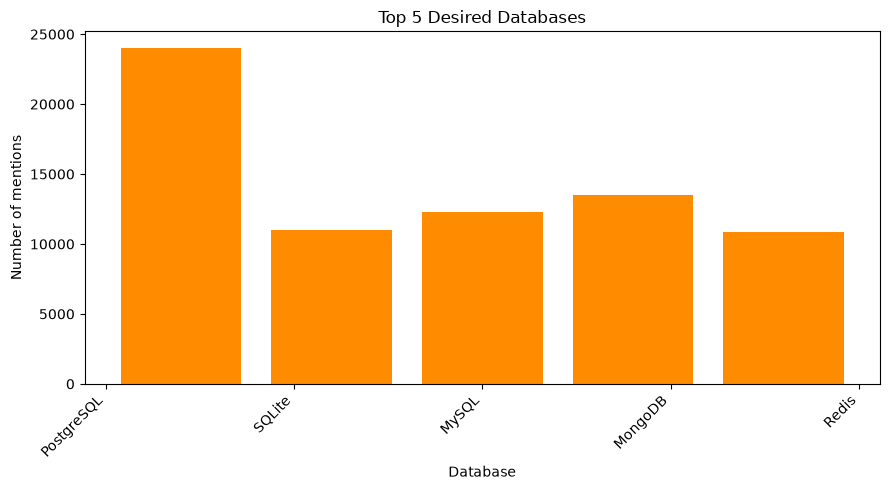

In [ ]:
## Write your code here
# count databases in the multi-response filed and show the top five most common databases
database_values = (survey_df['DatabaseWantToWorkWith'].dropna()
                  .astype(str).str.split(';').explode().str.strip())
database_counts = database_values[database_values.ne('')].value_counts().head(5)
print(database_counts)
plt.figure(figsize=(9, 5))
plt.hist(database_values[database_values.isin(database_counts.index)],
         bins=len(database_counts), rwidth=0.8, color='darkorange')
plt.xticks(range(len(database_counts)), database_counts.index, rotation=45, ha='right') # Set x-ticks to database names
plt.title('Top 5 Desired Databases')
plt.xlabel('Database')
plt.ylabel('Number of mentions')
plt.tight_layout()
plt.show()

**3.2 Histogram of Preferred Work Locations (`RemoteWork`)**


Objective: Use a histogram to explore the distribution of preferred work arrangements (`remote work`).


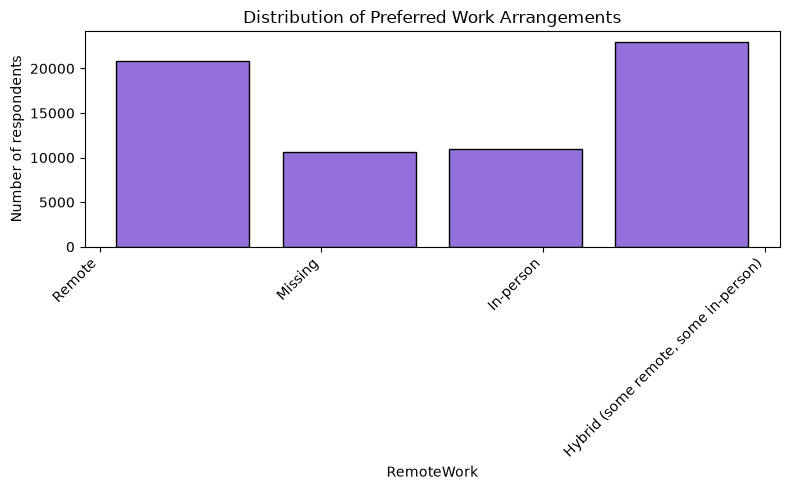

In [35]:
## Write your code here
remote_data= survey_df['RemoteWork'].fillna('Missing')

remote_codes, remote_categories=pd.factorize(remote_data)

plt.figure(figsize=(8,5))
plt.hist(remote_codes, bins=len(remote_categories), rwidth=0.8, color='mediumpurple', edgecolor='black')
plt.xticks(range(len(remote_categories)), remote_categories, rotation=45, ha='right')
plt.title('Distribution of Preferred Work Arrangements')
plt.xlabel('RemoteWork')
plt.ylabel('Number of respondents')
plt.tight_layout()
plt.show()

### 4. Visualizing Comparison of Data


**4.1 Histogram of Median CompTotal for Ages 45 to 60**


Objective: Plot the histogram for `CompTotal` within the age group 45 to 60 to analyze compensation distribution among mid-career respondents.


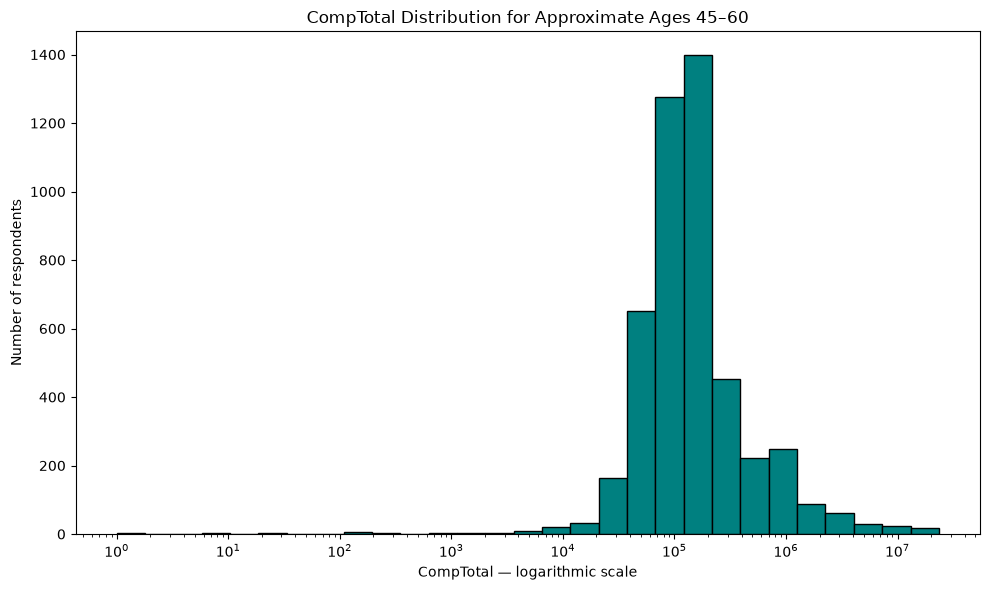

In [39]:
## Write your code here
age_mapping = {
    "Under 18 years old": 17,
    "18-24 years old": 21,
    "25-34 years old": 29,
    "35-44 years old": 39,
    "45-54 years old": 49,
    "55-64 years old": 59,
    "65 years or older": 70
}
hist_df = survey_df.copy()

hist_df["Age_numeric"] = hist_df["Age"].map(age_mapping)

hist_df["CompTotal"] = pd.to_numeric(
    hist_df["CompTotal"],
    errors="coerce"
)

hist_df = hist_df[
    hist_df["Age_numeric"].between(45, 60)
].dropna(subset=["CompTotal"])

hist_df = hist_df[
    hist_df["CompTotal"] > 0
]

# Limita il grafico al 99° percentile per evitare che gli outlier
# rendano invisibile la distribuzione principale
upper_limit = hist_df["CompTotal"].quantile(0.99)

hist_df = hist_df[
    hist_df["CompTotal"] <= upper_limit
]

bins = np.logspace(
    np.log10(hist_df["CompTotal"].min()),
    np.log10(hist_df["CompTotal"].max()),
    30
)

plt.figure(figsize=(10, 6))

plt.hist(
    hist_df["CompTotal"],
    bins=bins,
    color="teal",
    edgecolor="black"
)

plt.xscale("log")
plt.title("CompTotal Distribution for Approximate Ages 45–60")
plt.xlabel("CompTotal — logarithmic scale")
plt.ylabel("Number of respondents")
plt.tight_layout()
plt.show()

**4.2 Histogram of Job Satisfaction (`JobSat`) by YearsCodePro**


Objective: Plot the histogram for `JobSat` scores based on respondents' years of professional coding experience.


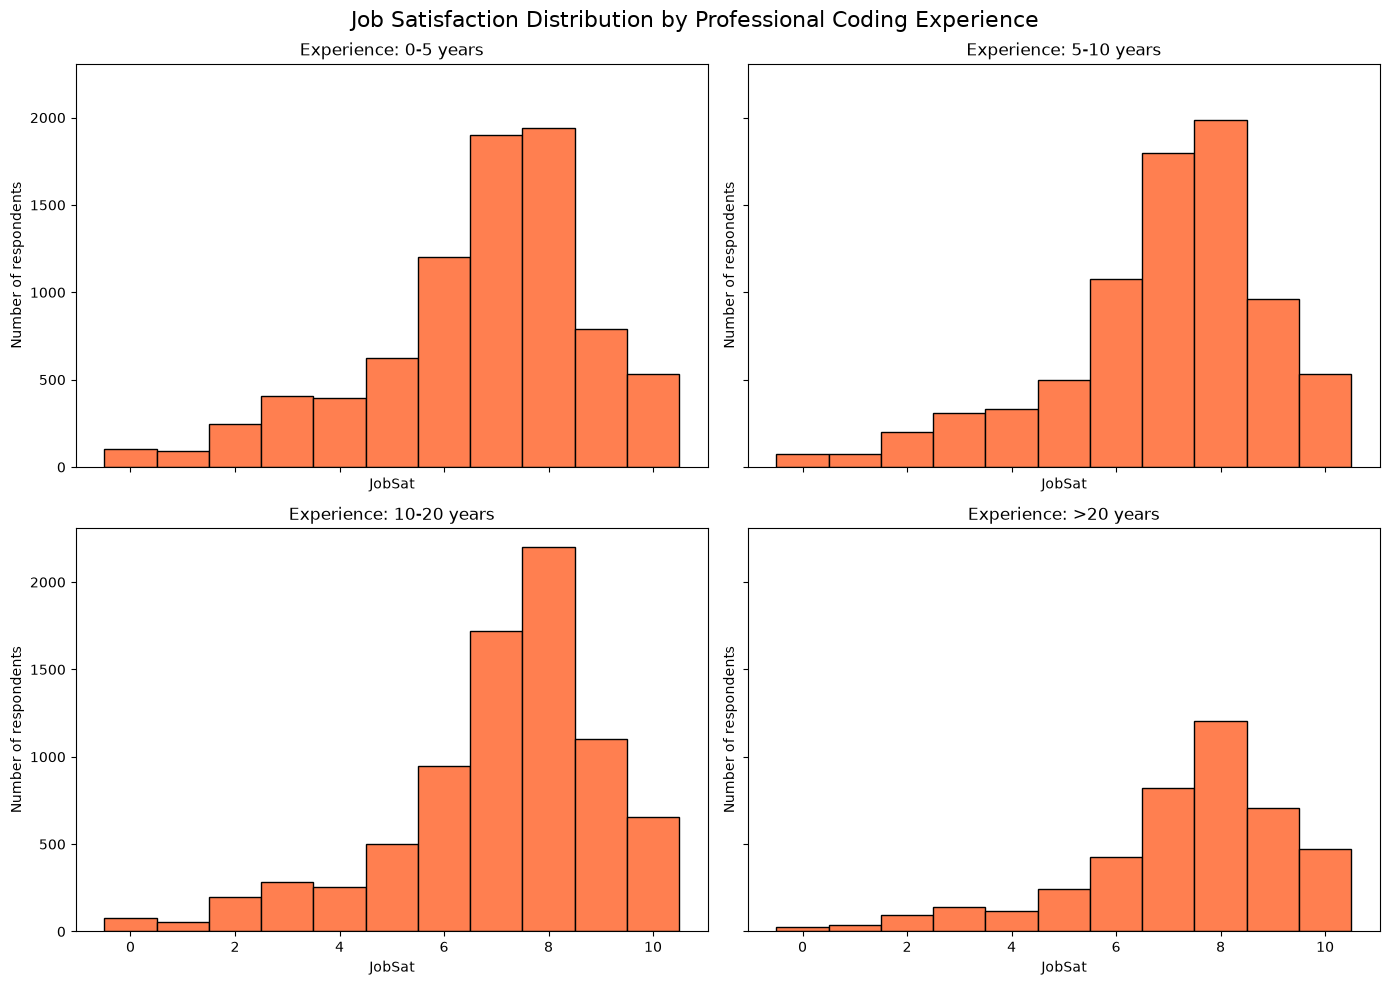

In [40]:
## Write your code here
job_sat_df = pd.DataFrame({
    "JobSat": pd.to_numeric(
        survey_df["JobSat"],
        errors="coerce"
    ),
    "YearsCodePro": (
        survey_df["YearsCodePro"]
        .replace({
            "Less than 1 year": "0.5",
            "More than 50 years": "51"
        })
        .pipe(pd.to_numeric, errors="coerce")
    )
}).dropna()

# Create bins for YearsCodePro
experience_bins = [
    -float("inf"),
    5,
    10,
    20,
    float("inf")
]

experience_labels = [
    "0-5",
    "5-10",
    "10-20",
    ">20"
]

job_sat_df["ExperienceGroup"] = pd.cut(
    job_sat_df["YearsCodePro"],
    bins=experience_bins,
    labels=experience_labels,
    right=False
)

bins = np.arange(-0.5, 11.5, 1)  # Bins for JobSat from 0 to 10
# Create a histogram for each experience group
fig,axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10), sharex=True, sharey=True)
axes=axes.flatten()

for i, group in enumerate(experience_labels):
    values = job_sat_df.loc[job_sat_df["ExperienceGroup"] == group, "JobSat"]
    
    axes[i].hist(values, bins=bins, edgecolor='black', color='coral')
    axes[i].set_title(f"Experience: {group} years")
    axes[i].set_xlabel("JobSat")
    axes[i].set_ylabel("Number of respondents")
    
plt.suptitle("Job Satisfaction Distribution by Professional Coding Experience", fontsize=16)
plt.tight_layout()
plt.show()

### Final step: Close the database connection


Once you've completed the lab, make sure to close the connection to the SQLite database:



In [41]:
conn.close()

### Summary


In this lab, you used histograms to visualize various aspects of the dataset, focusing on:

- Distribution of compensation, coding experience, and work hours.

- Relationships in compensation across age groups and work status.

- Composition of data by desired databases and work environments.

- Comparisons of job satisfaction across years of experience.

Histograms helped reveal patterns and distributions in the data, enhancing your understanding of developer demographics and preferences.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


Copyright © IBM Corporation. All rights reserved.
